<a href="https://colab.research.google.com/github/fabrice12/Threads-App-Clone/blob/main/eicv.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DUSHIME RENE FABRICE 216073618
# Clustering Rural Livelihood Strategies Using Unsupervised Learning

This notebook reproduces the rural livelihood clustering workflow for the EICV data. It combines many household/person/income/asset files using `hhid`, keeps rural households, builds household-level livelihood features, evaluates K-means cluster metrics, and generates the final `k=4` cluster interpretation used in the report.

## 1. Setup

The full reusable pipeline is stored in `scripts/livelihood_clustering.py`. This notebook imports those functions and runs them step by step so the analysis remains clear and reproducible.

In [14]:
from pathlib import Path
import sys
import os
import pandas as pd
from google.colab import drive

# 1. Mount Drive
drive.mount('/content/drive', force_remount=True)

# 2. Set the absolute path to your project
# Double check: Is it 'kmeans' or 'KMeans'? Case matters!
PROJECT_ROOT = "/content/drive/MyDrive/kmeans"

# 3. Change directory and add to sys.path
os.chdir(PROJECT_ROOT)
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

# 4. Define paths using Pathlib
ROOT = Path(PROJECT_ROOT)
DATA = ROOT / "data"
OUTPUTS = ROOT / "outputs_k4"
OUTPUTS.mkdir(exist_ok=True)
!touch /content/drive/MyDrive/kmeans/scripts/__init__.py
# 5. Now import
try:
    from scripts import livelihood_clustering as lc
    print("✅ Success: livelihood_clustering imported.")
except ImportError as e:
    print(f"❌ Error: {e}")
    print("Contents of current directory:", os.listdir())

# Formatting
pd.set_option("display.max_columns", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("Project folder:", ROOT)
print("Data folder exists:", DATA.exists())

Mounted at /content/drive
✅ Success: livelihood_clustering imported.
Project folder: /content/drive/MyDrive/kmeans
Data folder exists: True


## 2. Files Used

The base household file is `CS_EICV7_poverty_file.dta`. Other files are summarized to household level and merged using `hhid`.

In [9]:
files_used = [
    "CS_EICV7_poverty_file.dta",
    "CS_S0_S1_S2_S3_S4_S6A_S6B_S6C_Person.dta",
    "CS_S01_S5_S7_Household.dta",
    "CS_S9A_transfers_out.dta",
    "CS_S9B_transfers_in.dta",
    "CS_S9D1_Direct_Support.dta",
    "CS_S9D2_Classic_Public_Work.dta",
    "CS_S9D3_Expanded_Public_Work.dta",
    "CS_S9D4_NSDS.dta",
    "CS_S9E_other_income.dta",
    "CS_S10A1_A2_credits.dta",
    "CS_S10B_durables.dta",
    "CS_S10C_Savings.dta",
]

pd.DataFrame({
    "file": files_used,
    "exists": [(DATA / f).exists() for f in files_used],
    "size_mb": [round((DATA / f).stat().st_size / 1024 / 1024, 2) if (DATA / f).exists() else np.nan for f in files_used],
})

,file,exists,size_mb
0,CS_EICV7_poverty_file.dta,True,2.310
1,CS_S0_S1_S2_S3_S4_S6A_S6B_S6C_Person.dta,True,27.400
2,CS_S01_S5_S7_Household.dta,True,3.150
3,CS_S9A_transfers_out.dta,True,9.260
4,CS_S9B_transfers_in.dta,True,3.880
5,CS_S9D1_Direct_Support.dta,True,1.800
6,CS_S9D2_Classic_Public_Work.dta,True,1.910
7,CS_S9D3_Expanded_Public_Work.dta,True,1.760
8,CS_S9D4_NSDS.dta,True,2.000
9,CS_S9E_other_income.dta,True,26.160


## 3. Rural Household Selection

Rural and urban classification comes from the `ur` variable in the EICV poverty file. We keep records where `ur = Rural`.

In [10]:
poverty_base = pd.read_stata(DATA / "CS_EICV7_poverty_file.dta", columns=["hhid", "ur"], convert_categoricals=True)
ur_counts = poverty_base["ur"].value_counts().rename_axis("residence_area").reset_index(name="households")
ur_counts

,residence_area,households
0,Rural,11060
1,Urban,3994


In [11]:
rural_households = poverty_base.loc[poverty_base["ur"].astype(str).str.lower().eq("rural"), "hhid"].nunique()
print(f"Rural households selected for clustering: {rural_households:,}")

Rural households selected for clustering: 11,060


## 4. Build the Household-Level Dataset

The merge process is:

1. Start from the household poverty file.
2. Keep only rural households.
3. Aggregate person-level and transaction-level files by `hhid`.
4. Left-merge all household summaries into one dataset.
5. Fill missing numeric values with zero, meaning the household had no matching record in that source file.

In [15]:
df = lc.build_dataset()
print("Final household-level dataset shape:", df.shape)
df.head()

Final household-level dataset shape: (11060, 66)


,hhid,province,district,ur,member,ae,weight,cons1,cons1ae,sol_jan,quintile,poverty,pov_jan,epov_jan,hh_size,adult_equivalent_size,consumption_ae,real_consumption_ae,log_consumption_ae,household_members_observed,farm_workers,wage_workers,nonfarm_business_workers,volunteer_unpaid_workers,temporarily_absent_workers,employee_workers,own_account_workers,total_usual_work_hours,total_actual_work_hours,monthly_job_earnings,sleeping_rooms,owns_livestock,received_one_cow,livestock_count,livestock_tlu_proxy,transfer_in_amount,transfer_in_s9bq0_yes,transfer_in_s9bq7_yes,transfer_out_amount,transfer_out_s9aq0_yes,transfer_out_s9aq6_yes,transfer_out_s9aq9_yes,transfer_out_s9aq11_yes,other_income_amount,other_income_s9eq2_yes,direct_support_amount,direct_support_s9d1q1_yes,direct_support_s9d1q2_yes,classic_public_work_amount,classic_public_work_s9d1q1_yes,classic_public_work_s9d2q1_yes,expanded_public_work_amount,expanded_public_work_s9d1q1_yes,expanded_public_work_s9d3q1_yes,nsds_amount,nsds_s9d1q1_yes,nsds_s9d4q1_yes,tried_loan,owes_money,loan_records,saving_account_members,tontine_members,durable_items_count,durable_current_value,work_diversification_count,social_protection_amount
0,300027,Kigali City,Nyarugenge,Rural,3.000,2.529,112.270,"3,560,510.500","1,407,645.625","1,289,469.375",Upper,Non Poor,Non Poor,Non Extreme Poor,3.000,2.529,"1,407,645.625","1,289,469.375",14.070,3,0,1,2,0,0,2,1,105.000,145.000,"129,910.000",1,1,0,4.000,0.040,0.000,0,0,"4,500.000",1,1,1,0,"6,000.000",1,0.000,0,0,0.000,0,0,0.000,0.000,0.000,0.000,0.000,0.000,0,0,0,5,2,12.000,"279,000.000",4,0.000
1,300028,Kigali City,Nyarugenge,Rural,6.000,4.986,112.270,"2,546,281.250","510,726.250","444,834.594",Poor,Moderately poor,Poor,Non Extreme Poor,6.000,4.986,"510,726.250","444,834.594",13.005,6,2,1,0,0,0,3,2,90.000,78.000,"48,400.000",3,0,0,0.000,0.000,"24,700.000",1,0,"2,550.000",1,1,1,0,"6,000.000",1,0.000,0,0,"198,000.000",1,1,0.000,0.000,0.000,0.000,0.000,0.000,0,0,0,1,0,7.000,"44,000.000",5,"198,000.000"
2,300029,Kigali City,Nyarugenge,Rural,5.000,3.281,112.270,"4,272,075.500","1,301,960.750","1,021,383.688",Mid/upper,Non Poor,Non Poor,Non Extreme Poor,5.000,3.281,"1,301,960.750","1,021,383.688",13.837,5,2,1,0,0,0,2,1,84.000,84.000,"60,000.000",3,1,0,10.000,0.100,"21,000.000",1,0,"29,000.000",1,1,1,1,"106,000.000",1,0.000,0,0,0.000,0,0,0.000,0.000,0.000,0.000,0.000,0.000,0,0,0,3,1,10.000,"248,000.000",5,0.000
3,300030,Kigali City,Nyarugenge,Rural,3.000,2.182,112.270,"1,328,978.750","608,964.688","501,174.500",Poor,Moderately poor,Poor,Non Extreme Poor,3.000,2.182,"608,964.688","501,174.500",13.125,3,2,0,0,0,0,2,1,60.000,40.000,"33,000.000",2,0,0,0.000,0.000,"3,000.000",1,0,"2,600.000",1,0,0,1,"6,000.000",1,0.000,0,0,0.000,0,0,0.000,0.000,0.000,0.000,0.000,0.000,0,1,2,2,0,4.000,"31,500.000",4,0.000
4,300031,Kigali City,Nyarugenge,Rural,5.000,3.022,112.270,"28,378,744.000","9,390,311.000","8,196,085.000",Upper,Non Poor,Non Poor,Non Extreme Poor,5.000,3.022,"9,390,311.000","8,196,085.000",15.919,5,0,2,1,0,0,2,0,110.000,110.000,"1,220,000.000",3,1,0,1.000,0.700,0.000,0,0,"60,000.000",1,1,0,0,"306,000.000",1,0.000,0,0,0.000,0,0,0.000,0.000,0.000,0.000,0.000,0.000,0,0,0,3,0,29.000,"9,266,500.000",4,0.000


## 5. Features Used for Clustering

Poverty status, quintile, and consumption are not used as clustering inputs. They are kept for interpretation after clustering. The clustering features mainly describe livelihood activities, income sources, savings/credit, livestock, and durable assets.

In [16]:
features, matrix, scaler = lc.prepare_features(df)
print("Number of clustering features:", features.shape[1])
features.head()

Number of clustering features: 24


,hh_size,adult_equivalent_size,farm_workers,wage_workers,nonfarm_business_workers,employee_workers,own_account_workers,total_usual_work_hours,log_monthly_job_earnings,owns_livestock,received_one_cow,livestock_count,livestock_tlu_proxy,log_transfer_in_amount,log_transfer_out_amount,log_other_income_amount,log_social_protection_amount,tried_loan,owes_money,saving_account_members,tontine_members,durable_items_count,log_durable_current_value,work_diversification_count
0,3.000,2.529,0,1,2,2,1,105.000,11.775,1,0,4.000,0.040,0.000,8.412,8.700,0.000,0,0,5,2,12.000,12.539,4
1,6.000,4.986,2,1,0,3,2,90.000,10.787,0,0,0.000,0.000,10.115,7.844,8.700,12.181,0,0,1,0,7.000,10.692,5
2,5.000,3.281,2,1,0,2,1,84.000,11.002,1,0,10.000,0.100,9.952,10.275,11.571,0.000,0,0,3,1,10.000,12.421,5
3,3.000,2.182,2,0,0,2,1,60.000,10.404,0,0,0.000,0.000,8.007,7.864,8.700,0.000,0,1,2,0,4.000,10.358,4
4,5.000,3.022,0,2,1,2,0,110.000,12.941,1,0,1.000,0.700,0.000,11.002,12.631,0.000,0,0,3,0,27.000,14.142,4


## 6. Model Metrics

We evaluate several values of `k` using:

- Inertia: lower is better, mainly for the elbow method.
- Silhouette score: higher is better.
- Calinski-Harabasz score: higher is better.
- Davies-Bouldin score: lower is better.
- Minimum cluster size: avoids tiny clusters.

In [17]:
auto_k, evaluation = lc.choose_k(matrix, max_k=8)
print("Automatically selected k:", auto_k)
evaluation

Automatically selected k: 2


,k,inertia,silhouette,calinski_harabasz,davies_bouldin,min_cluster_size,passes_min_cluster_size
0,2,"222,472.343",0.149,"2,135.714",2.199,4737,True
1,3,"208,734.222",0.090,"1,501.904",2.610,2311,True
2,4,"197,092.033",0.087,"1,278.013",2.461,2055,True
3,5,"188,980.131",0.092,"1,118.194",2.268,572,True
4,6,"183,143.858",0.088,993.431,2.391,553,True
5,7,"177,859.665",0.078,907.108,2.424,551,True
6,8,"172,706.744",0.079,847.754,2.332,548,True


## 7. Fit the 4-Cluster Model

The automatic metrics favor `k=2`, but for interpretation and reporting we also use `k=4`, which gives clearer livelihood profiles: wage, low-diversification, savings + asset, and livestock.

In [18]:
REPORT_K = 4
model = KMeans(n_clusters=REPORT_K, random_state=lc.RANDOM_STATE, n_init=30)
labels = model.fit_predict(matrix)

df["cluster"] = labels
feature_z = pd.DataFrame(matrix, columns=features.columns).groupby(df["cluster"].to_numpy()).mean()
cluster_names = lc.describe_cluster_names(feature_z)
df["cluster_name"] = df["cluster"].map(cluster_names)

cluster_counts = (
    df.groupby(["cluster", "cluster_name"])
      .size()
      .reset_index(name="households")
)
cluster_counts["percent"] = cluster_counts["households"] / len(df) * 100
cluster_counts

,cluster,cluster_name,households,percent
0,0,wage,3343,30.226
1,1,low-diversification,2705,24.458
2,2,savings + asset,2055,18.580
3,3,livestock,2957,26.736


## 8. Cluster Profiles

These tables help explain what each cluster means.

In [19]:
summary_cols = [
    "hh_size",
    "adult_equivalent_size",
    "farm_workers",
    "wage_workers",
    "nonfarm_business_workers",
    "monthly_job_earnings",
    "owns_livestock",
    "livestock_tlu_proxy",
    "transfer_in_amount",
    "other_income_amount",
    "social_protection_amount",
    "saving_account_members",
    "durable_current_value",
    "work_diversification_count",
    "real_consumption_ae",
    "log_consumption_ae",
    "weight",
]

profile = df.groupby(["cluster", "cluster_name"])[summary_cols].mean()
profile

,,hh_size,adult_equivalent_size,farm_workers,wage_workers,nonfarm_business_workers,monthly_job_earnings,owns_livestock,livestock_tlu_proxy,transfer_in_amount,other_income_amount,social_protection_amount,saving_account_members,durable_current_value,work_diversification_count,real_consumption_ae,log_consumption_ae,weight
cluster,cluster_name,,,,,,,,,,,,,,,,,
0,wage,4.413,2.960,1.572,0.721,0.439,"83,307.099",0.471,0.181,"24,112.130","179,158.985","12,071.906",2.650,"140,279.353",4.466,"810,845.188",13.471,209.743
1,low-diversification,2.594,1.806,1.048,0.208,0.107,"27,034.729",0.219,0.066,"10,353.652","71,354.026","16,825.350",1.169,"37,762.828",3.217,"780,481.000",13.442,214.885
2,savings + asset,6.181,4.367,2.858,0.650,0.739,"91,657.980",0.939,1.565,"30,747.693","612,522.649","7,761.871",4.474,"321,138.048",4.526,"896,846.250",13.597,208.167
3,livestock,3.950,2.702,1.897,0.064,0.125,"5,017.855",0.871,0.644,"21,190.984","315,648.539","7,635.516",2.352,"122,083.768",3.717,"852,645.875",13.566,208.239


In [20]:
poverty_share = pd.crosstab(
    [df["cluster"], df["cluster_name"]],
    df["poverty"],
    normalize="index",
)
poverty_share

,poverty,Severaly Poor,Moderately poor,Non Poor
cluster,cluster_name,,,
0,wage,0.067,0.264,0.669
1,low-diversification,0.071,0.273,0.656
2,savings + asset,0.034,0.164,0.802
3,livestock,0.017,0.187,0.795


In [21]:
quintile_share = pd.crosstab(
    [df["cluster"], df["cluster_name"]],
    df["quintile"],
    normalize="index",
)
quintile_share

,quintile,Poor,Poor/mid,Mid,Mid/upper,Upper
cluster,cluster_name,,,,,
0,wage,0.244,0.222,0.215,0.191,0.128
1,low-diversification,0.253,0.230,0.214,0.203,0.099
2,savings + asset,0.139,0.194,0.249,0.255,0.163
3,livestock,0.130,0.227,0.261,0.258,0.124


## 9. Save Outputs and Visualizations

The notebook writes the same outputs to `outputs_k4/`.

In [22]:
lc.OUTPUTS = OUTPUTS

evaluation.to_csv(OUTPUTS / "cluster_evaluation.csv", index=False)
features.groupby(df["cluster"]).mean().to_csv(OUTPUTS / "cluster_feature_means.csv")
feature_z.to_csv(OUTPUTS / "cluster_feature_zscores.csv")
profile.to_csv(OUTPUTS / "cluster_profile.csv")
poverty_share.to_csv(OUTPUTS / "cluster_poverty_share.csv")
quintile_share.to_csv(OUTPUTS / "cluster_quintile_share.csv")
df.to_csv(OUTPUTS / "rural_livelihood_clusters.csv", index=False)

lc.save_plots(evaluation, matrix, labels)
lc.save_interpretation_plots(df, feature_z, poverty_share, quintile_share)
lc.write_report(df, evaluation, REPORT_K, cluster_names, profile)

print("Outputs saved to:", OUTPUTS)

Outputs saved to: /content/drive/MyDrive/kmeans/outputs_k4


## 10. Visualizations

cluster_sizes.png


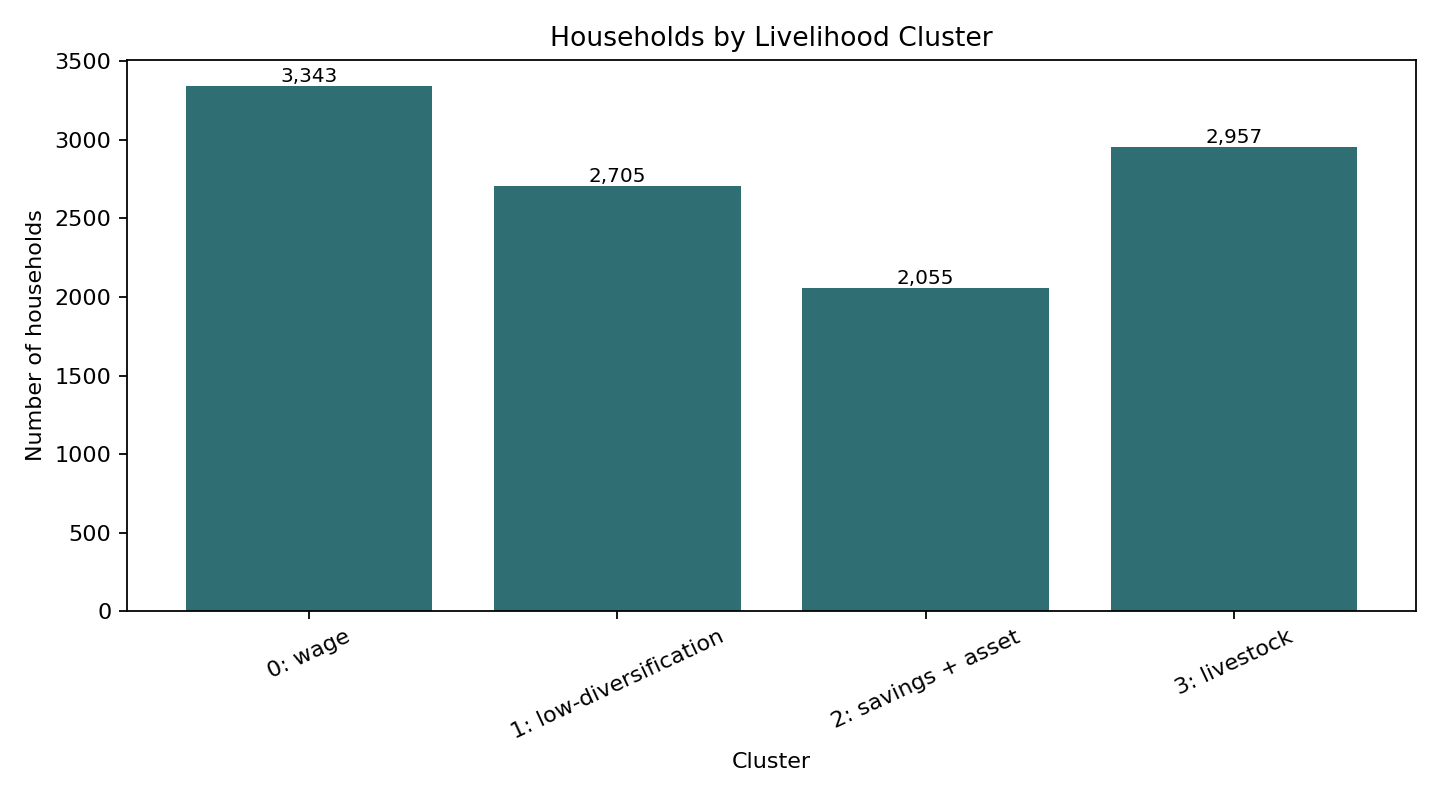

cluster_evaluation.png


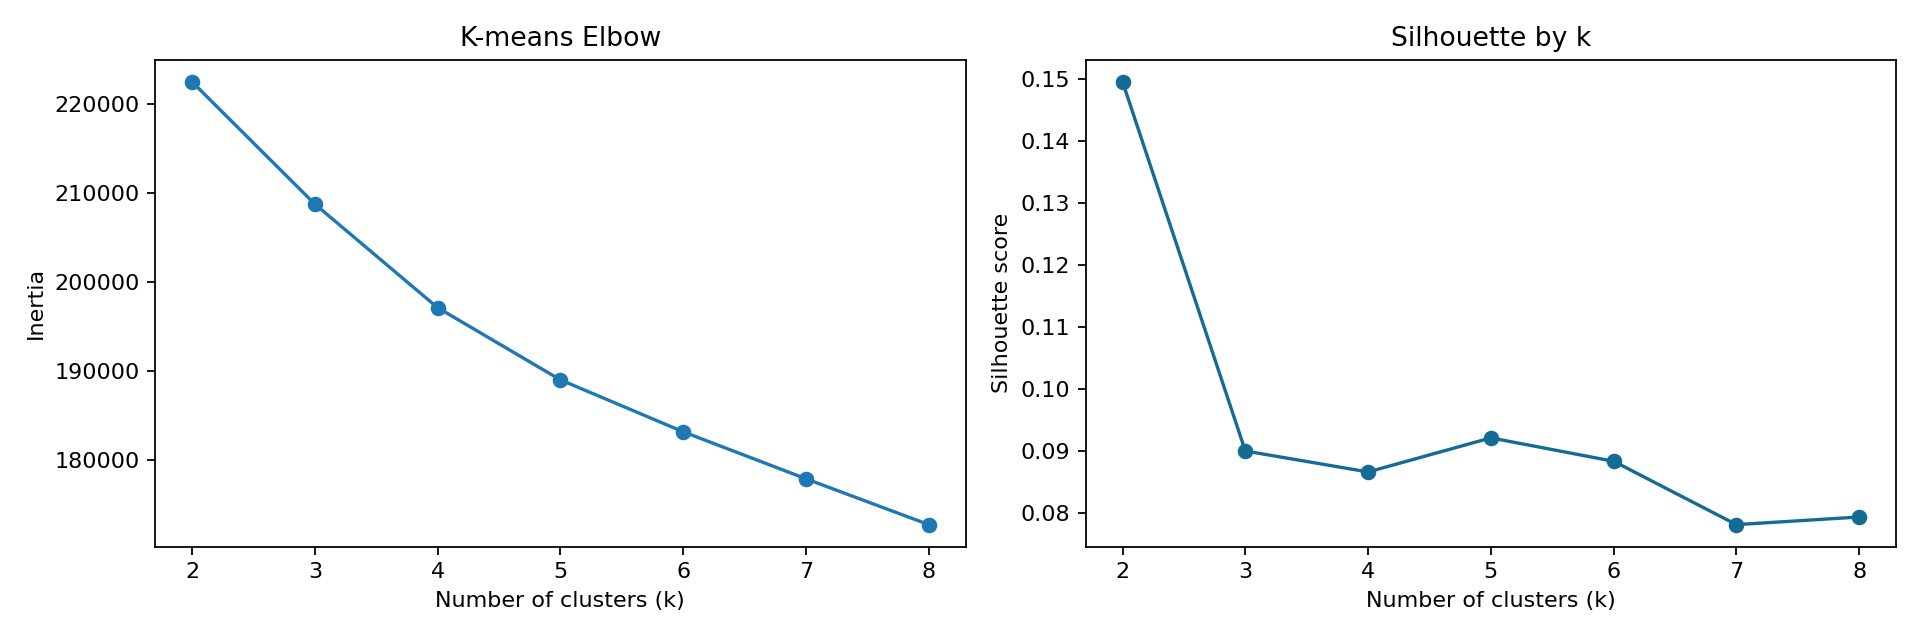

cluster_pca_scatter.png


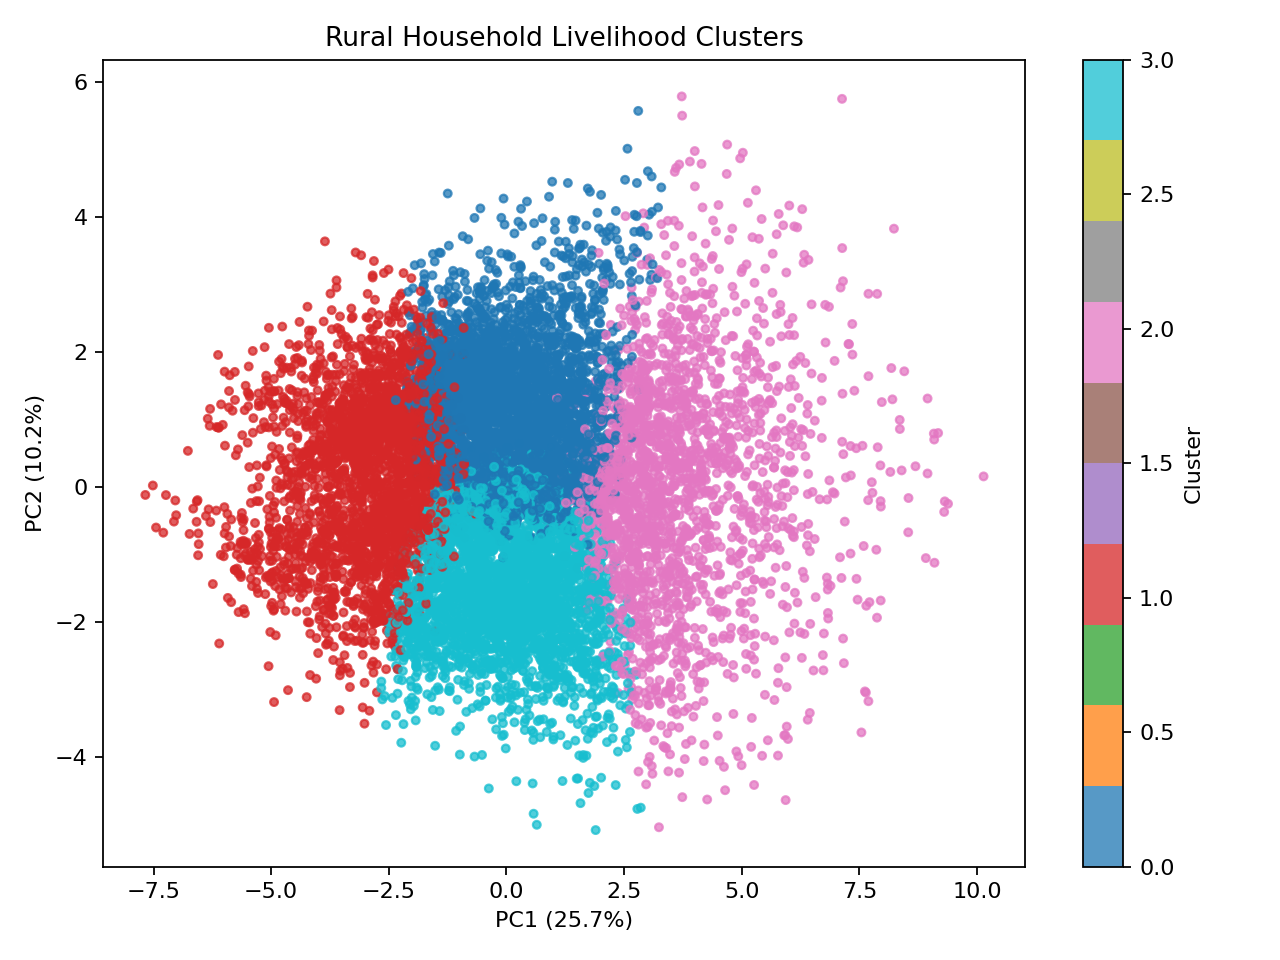

cluster_feature_heatmap.png


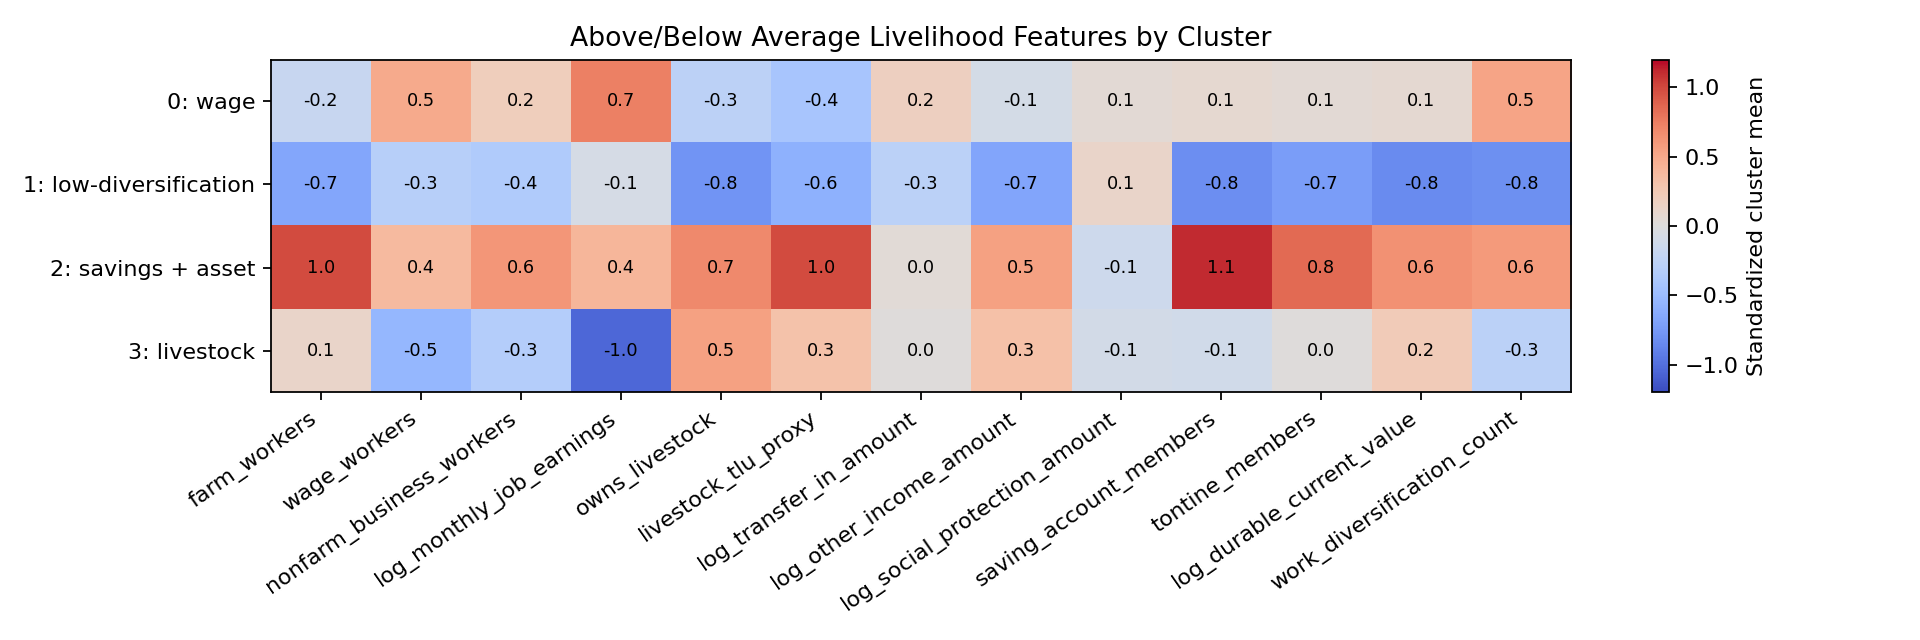

poverty_status_by_cluster.png


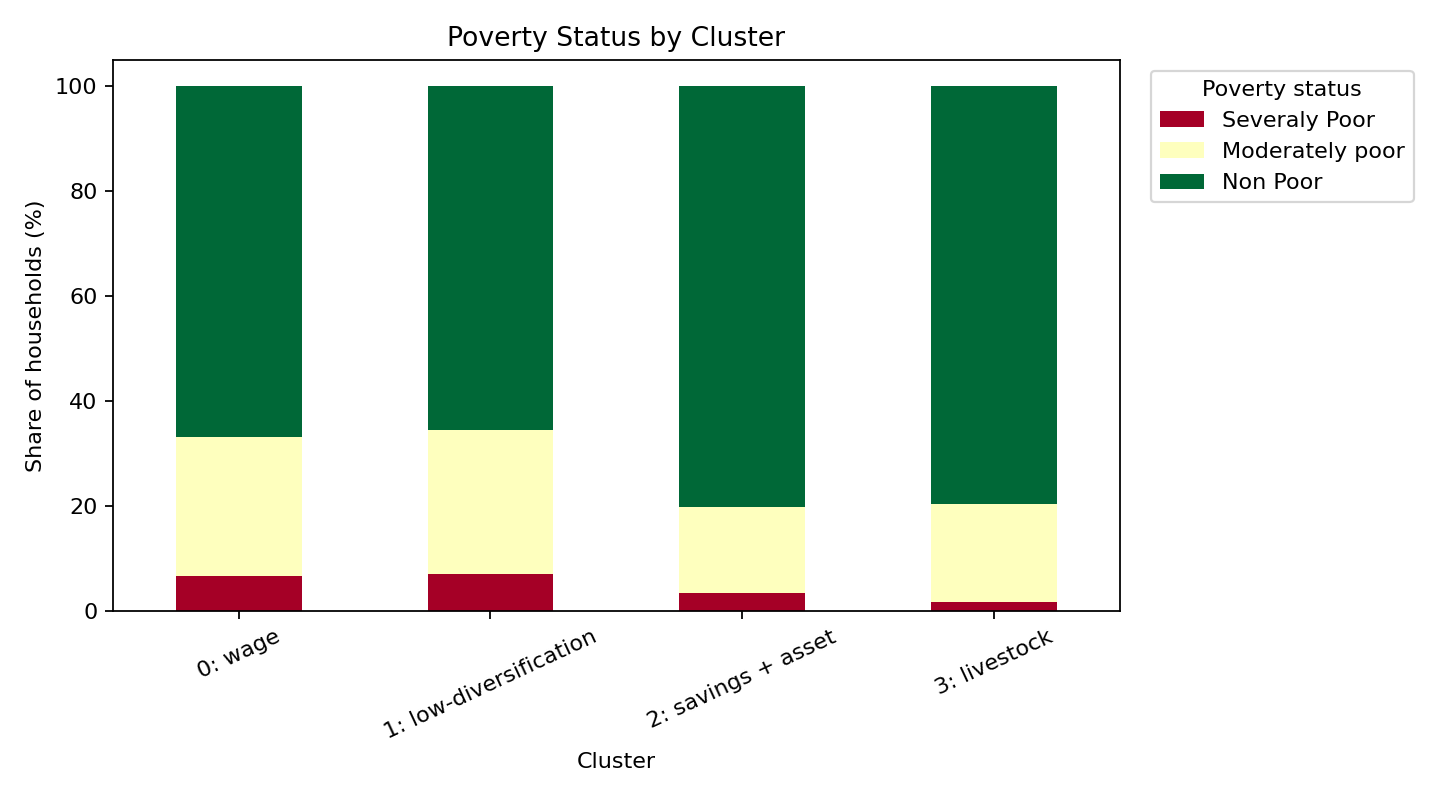

quintile_by_cluster.png


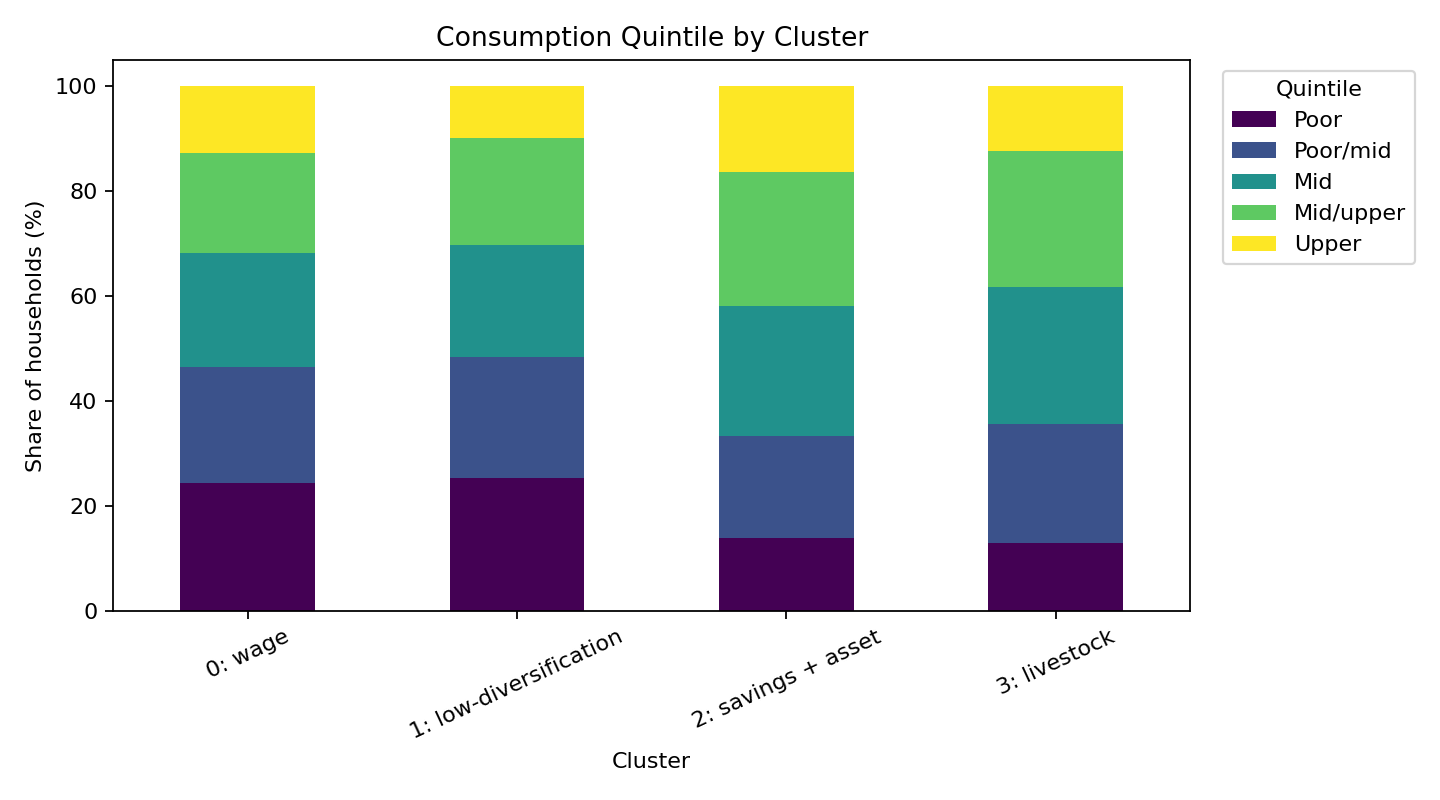

income_assets_livestock_bubble.png


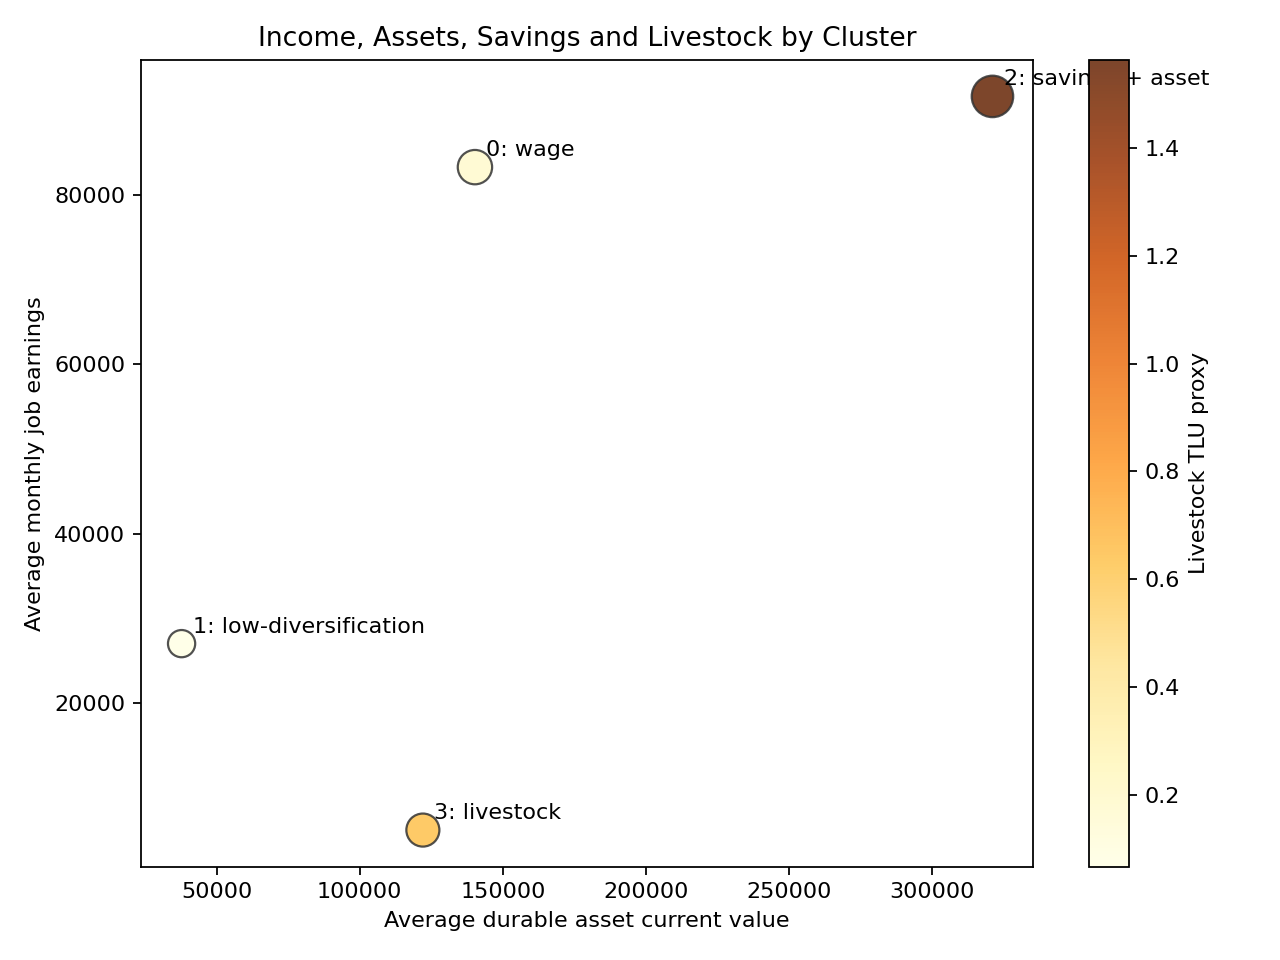

In [23]:
for image_name in [
    "cluster_sizes.png",
    "cluster_evaluation.png",
    "cluster_pca_scatter.png",
    "cluster_feature_heatmap.png",
    "poverty_status_by_cluster.png",
    "quintile_by_cluster.png",
    "income_assets_livestock_bubble.png",
]:
    print(image_name)
    display(Image(filename=str(OUTPUTS / image_name)))

## 11. Interpretation Summary

- **Wage cluster:** households with stronger wage employment and job earnings.
- **Low-diversification cluster:** households with fewer livelihood sources, lower assets, fewer savings members, and generally higher vulnerability.
- **Savings + asset cluster:** households with stronger savings participation, durable assets, non-farm activity, and higher diversification.
- **Livestock cluster:** households strongly linked to livestock and farm-based livelihoods, with lower wage income.

The clusters should be interpreted as livelihood profiles rather than perfectly separated groups, because rural households often combine several livelihood activities.